# Common redshift-prior reweighting: flow, EAZY, and LePhare

Read the saved independent-split reweighting experiment and generate coverage
and PIT figures. Regenerate inputs with `bin/coverage_prior_all_models.py`
after `bin/coverage_prior_correction.py`. Both n(z) estimates come from
separate spatial training/validation regions, not the 5,083 evaluation objects.

The same ratio is applied to the four photometric methods. The fifth
method is an existing flow trained by maximum likelihood with secure spec-z
labels: 22,604 training objects and 4,803 validation objects, using the same
architecture and noisy six-band inputs as the COSMOS-PDF flow. Its original
predictions are shown without another parent-to-spec reweighting because it
already learns the spectroscopically selected training population.
EAZY's existing priors differ
from the stacked COSMOS parent distribution, so this is a common reweighting
sensitivity experiment, not an exact replacement of EAZY's implicit prior.
The COSMOS PDF FULL flow uses six bands; it is distinct from the full-photometry
LePhare teacher. Flow reweighting was integrated on 4,097 inverse-CDF nodes
in posterior probability space, using exact original PIT values; a second,
coarser resolution checks convergence. No models were retrained.

The supplied summary includes four smoothing widths, 1,000 paired galaxy
bootstrap intervals conditional on the fitted ratio, and numerical checks.


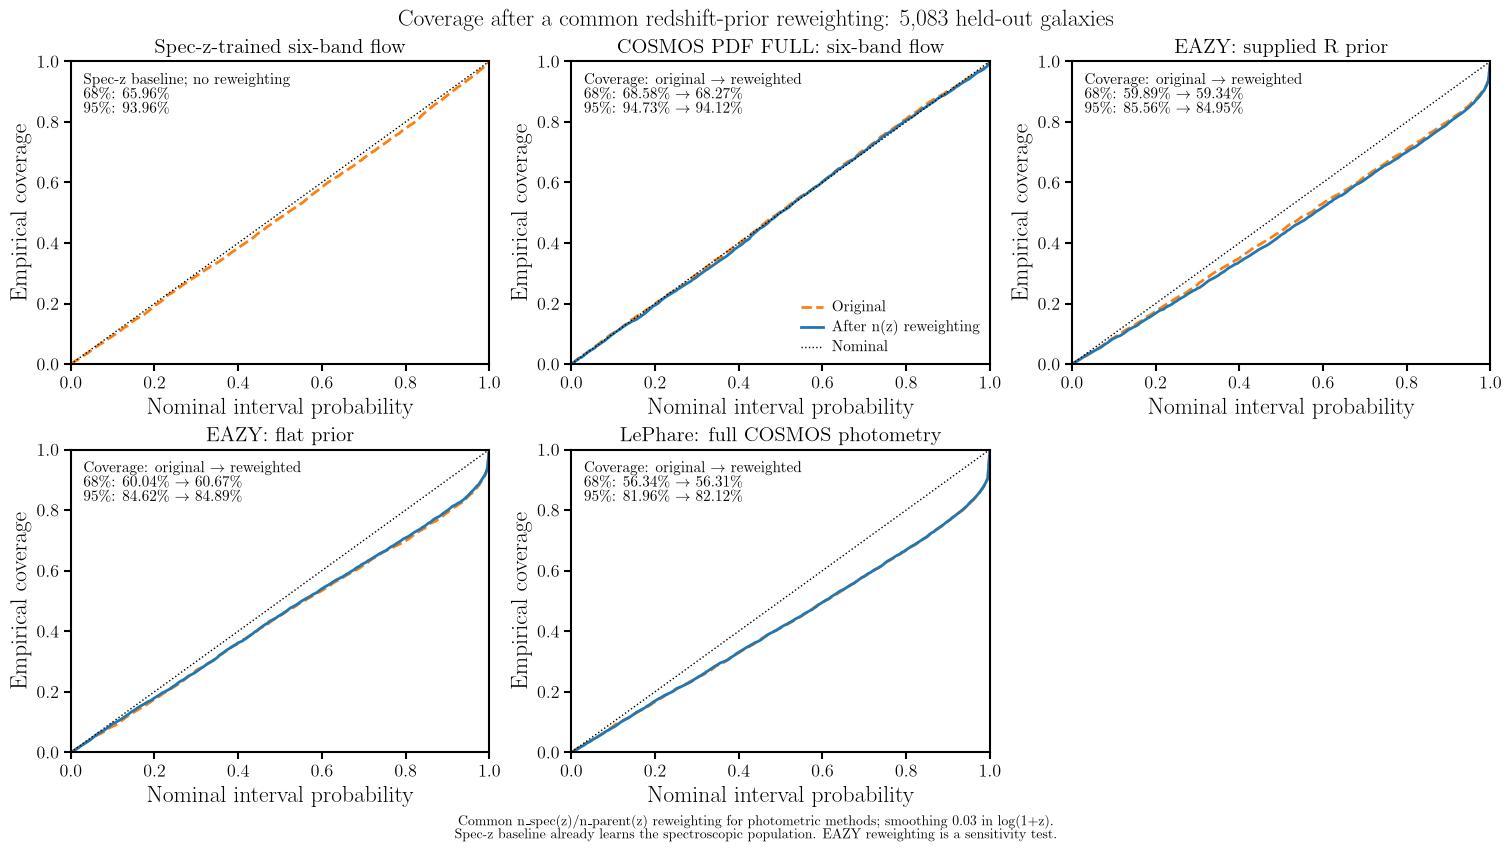

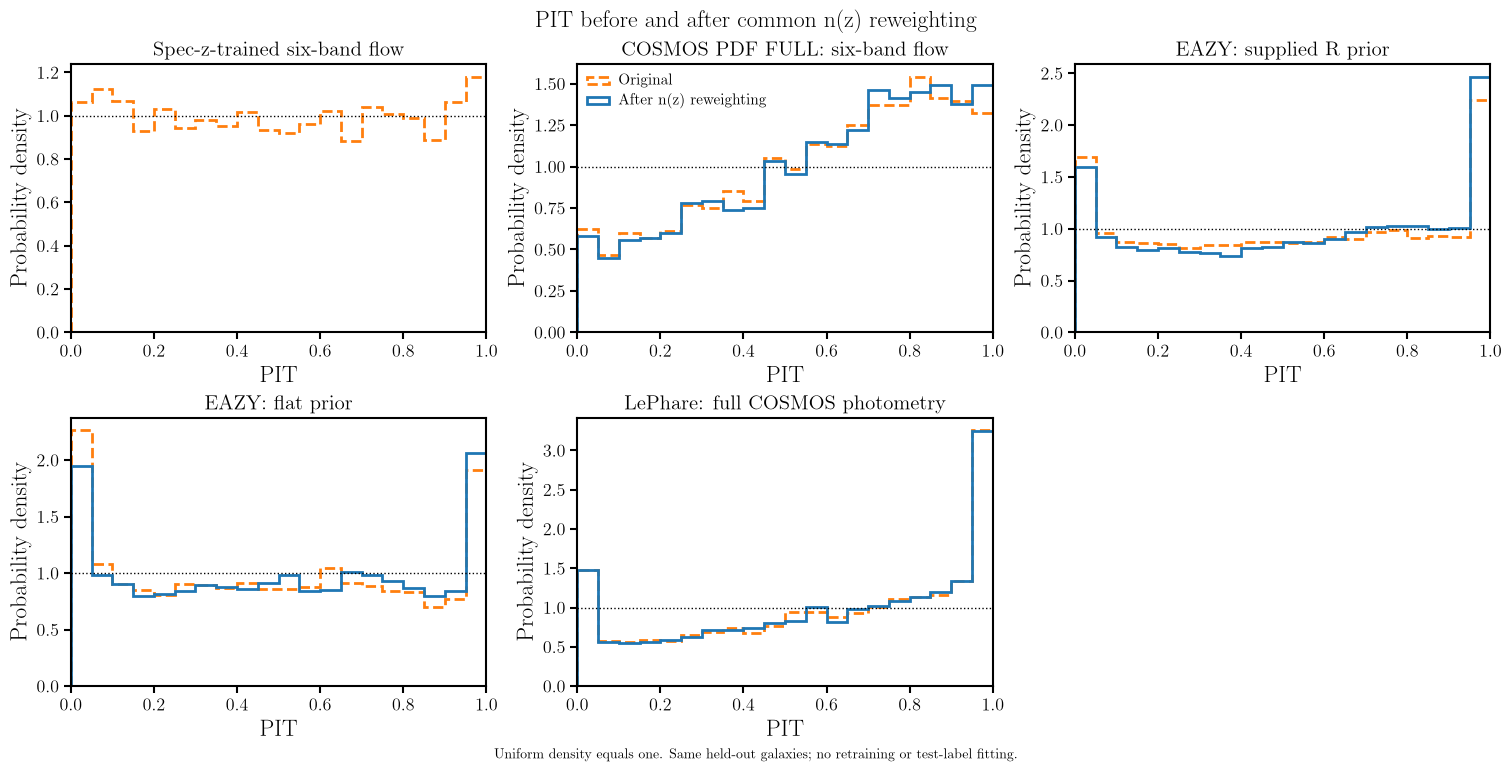

In [1]:

from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt

ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents]
          if (p/'paper/data/predictions.npz').exists())
OUT=ROOT/'results/coverage_prior_correction'
report=json.loads((OUT/'all_models_summary.json').read_text())
with np.load(OUT/'all_models_diagnostics.npz') as f:
    d={k:f[k] for k in f.files}
assert report['n_test']==len(d['id'])==5083
names=['broadband_spec_flow','cosmos_pdf_flow','eazy_rprior','eazy_six_band','lephare_full_cosmos']
labels=['Spec-z-trained six-band flow','COSMOS PDF FULL: six-band flow','EAZY: supplied R prior',
        'EAZY: flat prior','LePhare: full COSMOS photometry']
alpha=np.unique(np.r_[np.linspace(0,1,201),.68,.95])
import sys
sys.path.insert(0,str(ROOT/'src'))
from pzflow.project_plot_style import set_style
set_style()
fig,axs=plt.subplots(2,3,figsize=(15,8.4),layout='constrained')
axs.flat[-1].set_visible(False)
for ax,name,title in zip(axs.flat,names,labels):
    for key,label,color,style in [('original','Original','C1','--'),
                                  ('h_0.030','After n(z) reweighting','C0','-')]:
        if f'{name}_pit_{key}' not in d:continue
        pit=d[f'{name}_pit_{key}']
        cov=(abs(2*pit[:,None]-1)<=alpha[None,:]).mean(axis=0)
        cov[0]=0;cov[-1]=1
        ax.plot(alpha,cov,color=color,ls=style,lw=2,label=label)
    ax.plot([0,1],[0,1],color='black',ls=':',lw=1,label='Nominal')
    m=report['models'][name]
    txt=('Coverage: original → reweighted\n' if 'h_0.030' in m else 'Spec-z baseline; no reweighting\n')+ '\n'.join(
        f'{c}%: {100*m["original"]["coverage"+str(c)]:.2f}%'+
        (f' → {100*m["h_0.030"]["coverage"+str(c)]:.2f}%' if 'h_0.030' in m else '')
        for c in [68,95])
    ax.text(.03,.96,txt,transform=ax.transAxes,va='top',fontsize=9,
            bbox={'facecolor':'white','edgecolor':'none','alpha':.85})
    ax.set(title=title,xlim=(0,1),ylim=(0,1),
           xlabel='Nominal interval probability',ylabel='Empirical coverage')
    ax.grid(alpha=.15)
axs.flat[1].legend(loc='lower right',fontsize=8)
fig.suptitle('Coverage after a common redshift-prior reweighting: 5,083 held-out galaxies',
             fontsize=14,fontweight='bold')
fig.supxlabel('Common n_spec(z)/n_parent(z) reweighting for photometric methods; smoothing 0.03 in log(1+z).\n'
              'Spec-z baseline already learns the spectroscopic population. EAZY reweighting is a sensitivity test.',fontsize=9)
fig.savefig(OUT/'all_models_coverage.png',dpi=180)
plt.show()

fig,axs=plt.subplots(2,3,figsize=(15,7.6),layout='constrained')
axs.flat[-1].set_visible(False)
for ax,name,title in zip(axs.flat,names,labels):
    for key,label,color,style in [('original','Original','C1','--'),
                                  ('h_0.030','After n(z) reweighting','C0','-')]:
        if f'{name}_pit_{key}' not in d:continue
        ax.hist(d[f'{name}_pit_{key}'],bins=np.linspace(0,1,21),density=True,
                histtype='step',color=color,ls=style,lw=2,label=label)
    ax.axhline(1,color='black',ls=':',lw=1)
    ax.set(title=title,xlim=(0,1),xlabel='PIT',ylabel='Probability density')
    ax.grid(alpha=.15)
axs.flat[1].legend(fontsize=8)
fig.suptitle('PIT before and after common n(z) reweighting',fontsize=14,fontweight='bold')
fig.supxlabel('Uniform density equals one. Same held-out galaxies; no retraining or test-label fitting.',fontsize=9)
fig.savefig(OUT/'all_models_pit.png',dpi=180)
plt.show()
